# Part one regression:

## Loading Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

BASE_PATH = "/kaggle/input/datasets/dgawlik/nyse"

prices = pd.read_csv(f"{BASE_PATH}/prices.csv")
prices_adjusted = pd.read_csv( f"{BASE_PATH}/prices-split-adjusted.csv")
fundamentals = pd.read_csv(f"{BASE_PATH}/fundamentals.csv")
securities = pd.read_csv(f"{BASE_PATH}/securities.csv")

datasets = {
    "prices": prices,
    # "prices_adjusted": prices_adjusted,
    # "fundamentals": fundamentals,
    # "securities": securities
}

for name, data in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"{name}: {data.shape}") # shape > (lignes, colones)
    print(data.head(3))
    print("\nColumns:", data.columns.tolist())
    print("\nMissing values:", data.isnull().sum().sum())


prices: (851264, 7)
                  date symbol        open       close         low        high  \
0  2016-01-05 00:00:00   WLTW  123.430000  125.839996  122.309998  126.250000   
1  2016-01-06 00:00:00   WLTW  125.239998  119.980003  119.940002  125.540001   
2  2016-01-07 00:00:00   WLTW  116.379997  114.949997  114.930000  119.739998   

      volume  
0  2163600.0  
1  2386400.0  
2  2489500.0  

Columns: ['date', 'symbol', 'open', 'close', 'low', 'high', 'volume']

Missing values: 0


###  Préparer le dataset pour l'analyse

## 1. Apply the Exploratory data analysis technics to understand and visualize the given Dataset.

Forme du dataset : (851264, 7)

Types de données et valeurs nulles :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    851264 non-null  object 
 1   symbol  851264 non-null  object 
 2   open    851264 non-null  float64
 3   close   851264 non-null  float64
 4   low     851264 non-null  float64
 5   high    851264 non-null  float64
 6   volume  851264 non-null  float64
dtypes: float64(5), object(2)
memory usage: 45.5+ MB
None

Statistiques descriptives :
                open          close            low           high  \
count  851264.000000  851264.000000  851264.000000  851264.000000   
mean       64.993618      65.011913      64.336541      65.639748   
std        75.203893      75.201216      74.459518      75.906861   
min         1.660000       1.590000       1.500000       1.810000   
25%        31.270000      31.292776      30.940

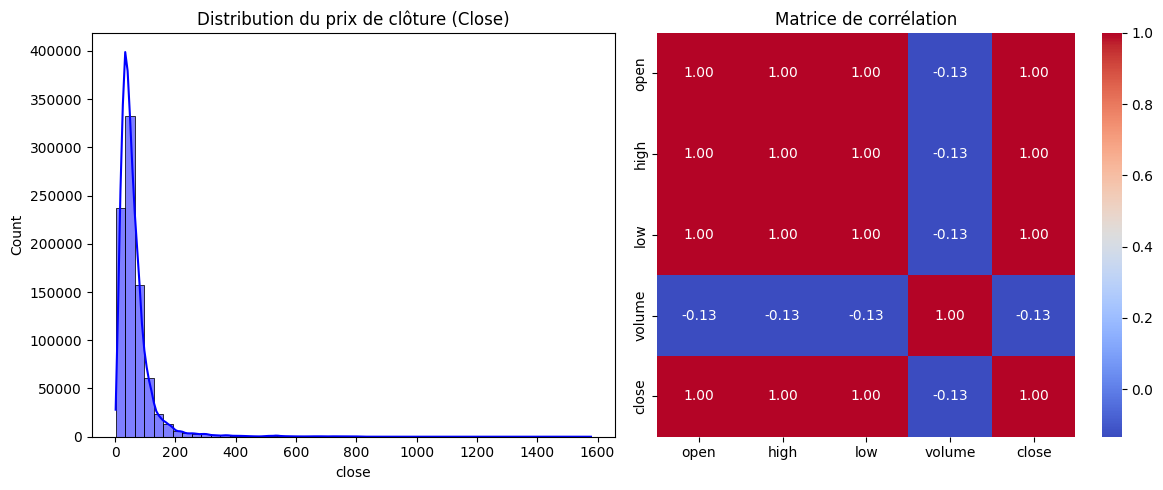

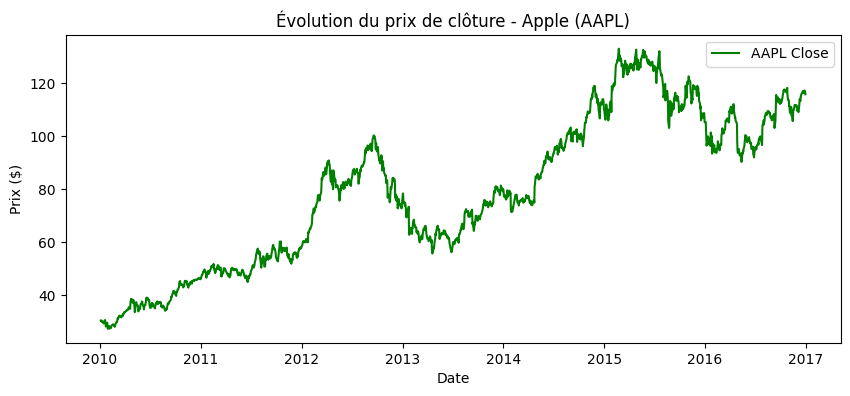

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Chargement des données (Adjusted Prices)
BASE_PATH = "/kaggle/input/datasets/dgawlik/nyse"

prices = pd.read_csv(f"{BASE_PATH}/prices-split-adjusted.csv")
df = prices
# 2. Aperçu général et vérification des valeurs manquantes
print("Forme du dataset :", df.shape)
print("\nTypes de données et valeurs nulles :")
print(df.info())
print("\nStatistiques descriptives :")
print(df.describe())

# 3. Visualisation de la distribution de la cible (Close)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['close'], bins=50, kde=True, color='blue')
plt.title('Distribution du prix de clôture (Close)')

# 4. Matrice de corrélation
plt.subplot(1, 2, 2)
numeric_df = df[['open', 'high', 'low', 'volume', 'close']]
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matrice de corrélation')
plt.tight_layout()
plt.show()

# 5. Évolution temporelle pour un exemple d'entreprise (ex: AAPL)
aapl = df[df['symbol'] == 'AAPL']
plt.figure(figsize=(10, 4))
plt.plot(pd.to_datetime(aapl['date']), aapl['close'], label='AAPL Close', color='green')
plt.title("Évolution du prix de clôture - Apple (AAPL)")
plt.xlabel("Date")
plt.ylabel("Prix ($)")
plt.legend()
plt.show()

## 2. Establish a Deep Neural network Architecture by using PyTorch library to handle the regression task.

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Séparation Features (X) et Target (y)
X = df[['open', 'high', 'low', 'volume']].values
y = df['close'].values.reshape(-1, 1)

# 2. Split Train / Test (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Standardisation
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

# 4. Conversion en Tenseurs PyTorch & DataLoaders
train_dataset = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32), 
                              torch.tensor(y_train_scaled, dtype=torch.float32))
test_dataset = TensorDataset(torch.tensor(X_test_scaled, dtype=torch.float32), 
                             torch.tensor(y_test_scaled, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

# 5. Définition du Modèle DNN de base
class BaseMLPRegressor(nn.Module):
    def __init__(self, input_dim):
        super(BaseMLPRegressor, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)  # 1 seule sortie car régression
        )
        
    def forward(self, x):
        return self.net(x)

model_base = BaseMLPRegressor(input_dim=4)
print(model_base)

BaseMLPRegressor(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 3. By using GridSearch tool from sklearn library chose the best hyper-parameters (learning rate ,optimizers, epoch, model architecture, etc) that will give an efficient model.

In [4]:
!pip install skorch -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 271.6/271.6 kB 4.8 MB/s eta 0:00:00


In [5]:
from skorch import NeuralNetRegressor
from sklearn.model_selection import GridSearchCV

# 1. Conversion explicite de X et y en float32
X_train_32 = X_train_scaled.astype(np.float32)
y_train_32 = y_train_scaled.astype(np.float32)

# 2. Wrapper skorch pour PyTorch
net = NeuralNetRegressor(
    module=BaseMLPRegressor,
    module__input_dim=4,
    criterion=nn.MSELoss,
    verbose=False
)

# 3. Grille d'hyperparamètres à tester
param_grid = {
    'lr': [0.001, 0.01],
    'optimizer': [optim.Adam, optim.SGD],
    'batch_size': [256, 512],
    'max_epochs': [10]
}

# 4. Exécution du GridSearch (sur 50 000 échantillons pour la vitesse)
grid = GridSearchCV(net, param_grid, refit=True, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
grid.fit(X_train_32[:50000], y_train_32[:50000])

print("Meilleurs Hyperparamètres trouvés :")
print(grid.best_params_)

Meilleurs Hyperparamètres trouvés :
{'batch_size': 256, 'lr': 0.001, 'max_epochs': 10, 'optimizer': <class 'torch.optim.adam.Adam'>}


## 4. Visualize the two graph (Loss / Epochs) and (Accuracy / Epochs) for both training and test data, give your interpretation.

Époque 01/15 | Train Loss: 0.0065 | Test Loss: 0.0001 | Test R2: 0.9999
Époque 02/15 | Train Loss: 0.0002 | Test Loss: 0.0002 | Test R2: 0.9998
Époque 03/15 | Train Loss: 0.0003 | Test Loss: 0.0001 | Test R2: 0.9999
Époque 04/15 | Train Loss: 0.0002 | Test Loss: 0.0002 | Test R2: 0.9998
Époque 05/15 | Train Loss: 0.0002 | Test Loss: 0.0003 | Test R2: 0.9997
Époque 06/15 | Train Loss: 0.0001 | Test Loss: 0.0001 | Test R2: 0.9999
Époque 07/15 | Train Loss: 0.0002 | Test Loss: 0.0001 | Test R2: 0.9999
Époque 08/15 | Train Loss: 0.0001 | Test Loss: 0.0001 | Test R2: 0.9999
Époque 09/15 | Train Loss: 0.0001 | Test Loss: 0.0001 | Test R2: 0.9999
Époque 10/15 | Train Loss: 0.0002 | Test Loss: 0.0002 | Test R2: 0.9998
Époque 11/15 | Train Loss: 0.0001 | Test Loss: 0.0003 | Test R2: 0.9997
Époque 12/15 | Train Loss: 0.0001 | Test Loss: 0.0001 | Test R2: 0.9999
Époque 13/15 | Train Loss: 0.0001 | Test Loss: 0.0001 | Test R2: 0.9999
Époque 14/15 | Train Loss: 0.0001 | Test Loss: 0.0002 | Test R2:

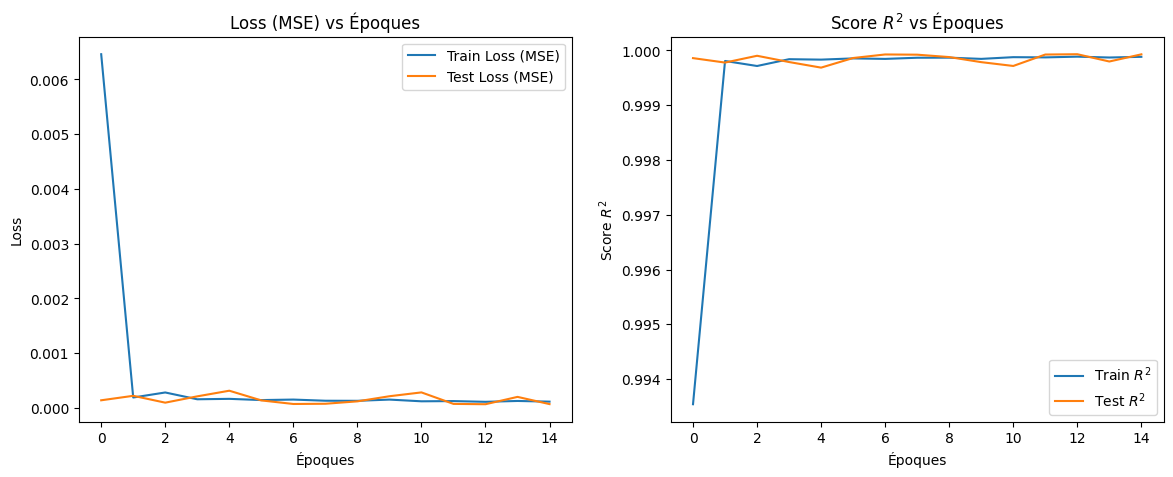

In [6]:
from sklearn.metrics import r2_score

def train_and_evaluate(model, train_loader, test_loader, epochs=15, lr=0.001):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    history = {'train_loss': [], 'test_loss': [], 'train_r2': [], 'test_r2': []}
    
    for epoch in range(epochs):
        # --- Mode Entraînement ---
        model.train()
        running_loss = 0.0
        y_true_train, y_pred_train = [], []
        
        for X_b, y_b in train_loader:
            optimizer.zero_grad()
            outputs = model(X_b)
            loss = criterion(outputs, y_b)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * X_b.size(0)
            y_true_train.extend(y_b.numpy())
            y_pred_train.extend(outputs.detach().numpy())
            
        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_r2 = r2_score(y_true_train, y_pred_train)
        
        # --- Mode Évaluation ---
        model.eval()
        running_test_loss = 0.0
        y_true_test, y_pred_test = [], []
        
        with torch.no_grad():
            for X_b, y_b in test_loader:
                outputs = model(X_b)
                loss = criterion(outputs, y_b)
                running_test_loss += loss.item() * X_b.size(0)
                y_true_test.extend(y_b.numpy())
                y_pred_test.extend(outputs.numpy())
                
        epoch_test_loss = running_test_loss / len(test_loader.dataset)
        epoch_test_r2 = r2_score(y_true_test, y_pred_test)
        df
        history['train_loss'].append(epoch_train_loss)
        history['test_loss'].append(epoch_test_loss)
        history['train_r2'].append(epoch_train_r2)
        history['test_r2'].append(epoch_test_r2)
        
        print(f"Époque {epoch+1:02d}/{epochs:02d} | Train Loss: {epoch_train_loss:.4f} | Test Loss: {epoch_test_loss:.4f} | Test R2: {epoch_test_r2:.4f}")
        
    return history

# Entraînement du modèle de base
history_base = train_and_evaluate(model_base, train_loader, test_loader, epochs=15, lr=0.001)

# Visualisation des graphiques
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique Loss
axes[0].plot(history_base['train_loss'], label='Train Loss (MSE)')
axes[0].plot(history_base['test_loss'], label='Test Loss (MSE)')
axes[0].set_title('Loss (MSE) vs Époques')
axes[0].set_xlabel('Époques')
axes[0].set_ylabel('Loss')
axes[0].legend()

# Graphique R2
axes[1].plot(history_base['train_r2'], label='Train $R^2$')
axes[1].plot(history_base['test_r2'], label='Test $R^2$')
axes[1].set_title('Score $R^2$ vs Époques')
axes[1].set_xlabel('Époques')
axes[1].set_ylabel('Score $R^2$')
axes[1].legend()

plt.show()

## 5. Apply several regularization techniques on your architecture then compare the obtained result with the first model.

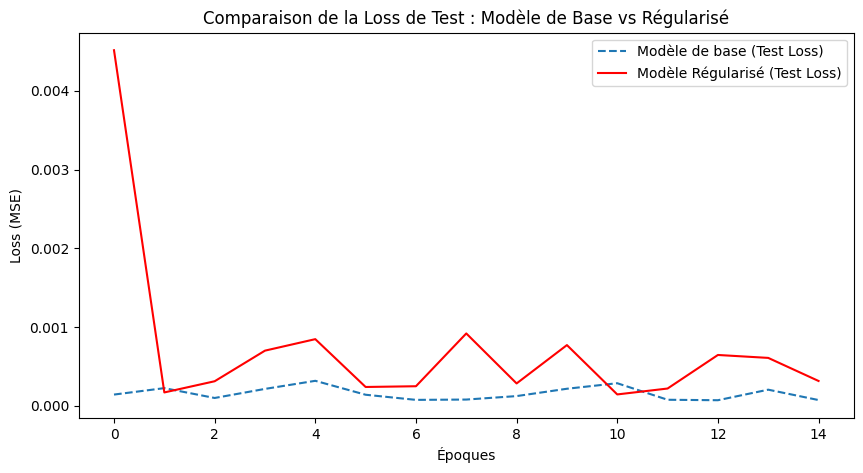

In [7]:
class CorrectedRegularizedMLP(nn.Module):
    def __init__(self, input_dim, dropout_rate=0.05):
        super(CorrectedRegularizedMLP, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        return self.net(x)

# 2. Instanciation de la nouvelle classe corrigée
model_reg = CorrectedRegularizedMLP(input_dim=4, dropout_rate=0.05)

# 3. Fonction d'entraînement avec Weight Decay (L2)
def train_regularized(model, train_loader, test_loader, epochs=15, lr=0.001, weight_decay=1e-4):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    
    history = {'train_loss': [], 'test_loss': [], 'train_r2': [], 'test_r2': []}
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        y_true_train, y_pred_train = [], []
        
        for X_b, y_b in train_loader:
            optimizer.zero_grad()
            outputs = model(X_b)
            loss = criterion(outputs, y_b)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * X_b.size(0)
            y_true_train.extend(y_b.numpy())
            y_pred_train.extend(outputs.detach().numpy())
            
        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_r2 = r2_score(y_true_train, y_pred_train)
        
        model.eval()
        running_test_loss = 0.0
        y_true_test, y_pred_test = [], []
        
        with torch.no_grad():
            for X_b, y_b in test_loader:
                outputs = model(X_b)
                loss = criterion(outputs, y_b)
                running_test_loss += loss.item() * X_b.size(0)
                y_true_test.extend(y_b.numpy())
                y_pred_test.extend(outputs.numpy())
                
        epoch_test_loss = running_test_loss / len(test_loader.dataset)
        epoch_test_r2 = r2_score(y_true_test, y_pred_test)
        
        history['train_loss'].append(epoch_train_loss)
        history['test_loss'].append(epoch_test_loss)
        history['train_r2'].append(epoch_train_r2)
        history['test_r2'].append(epoch_test_r2)
        
    return history

# 4. Lancement de l'entraînement
history_reg = train_regularized(model_reg, train_loader, test_loader, epochs=15)

# 5. Comparaison visuelle des deux modèles
plt.figure(figsize=(10, 5))
plt.plot(history_base['test_loss'], label='Modèle de base (Test Loss)', linestyle='--')
plt.plot(history_reg['test_loss'], label='Modèle Régularisé (Test Loss)', color='red')
plt.title('Comparaison de la Loss de Test : Modèle de Base vs Régularisé')
plt.xlabel('Époques')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.show()

### L2 test 

Époque 01/15 | Train Loss: 0.0069 | Test Loss: 0.0002 | Test R2: 0.9998
Époque 02/15 | Train Loss: 0.0002 | Test Loss: 0.0002 | Test R2: 0.9998
Époque 03/15 | Train Loss: 0.0002 | Test Loss: 0.0002 | Test R2: 0.9998
Époque 04/15 | Train Loss: 0.0002 | Test Loss: 0.0003 | Test R2: 0.9997
Époque 05/15 | Train Loss: 0.0002 | Test Loss: 0.0002 | Test R2: 0.9998
Époque 06/15 | Train Loss: 0.0002 | Test Loss: 0.0002 | Test R2: 0.9998
Époque 07/15 | Train Loss: 0.0002 | Test Loss: 0.0002 | Test R2: 0.9998
Époque 08/15 | Train Loss: 0.0002 | Test Loss: 0.0004 | Test R2: 0.9996
Époque 09/15 | Train Loss: 0.0002 | Test Loss: 0.0002 | Test R2: 0.9998
Époque 10/15 | Train Loss: 0.0002 | Test Loss: 0.0002 | Test R2: 0.9998
Époque 11/15 | Train Loss: 0.0002 | Test Loss: 0.0002 | Test R2: 0.9998
Époque 12/15 | Train Loss: 0.0002 | Test Loss: 0.0002 | Test R2: 0.9998
Époque 13/15 | Train Loss: 0.0002 | Test Loss: 0.0002 | Test R2: 0.9998
Époque 14/15 | Train Loss: 0.0002 | Test Loss: 0.0002 | Test R2:

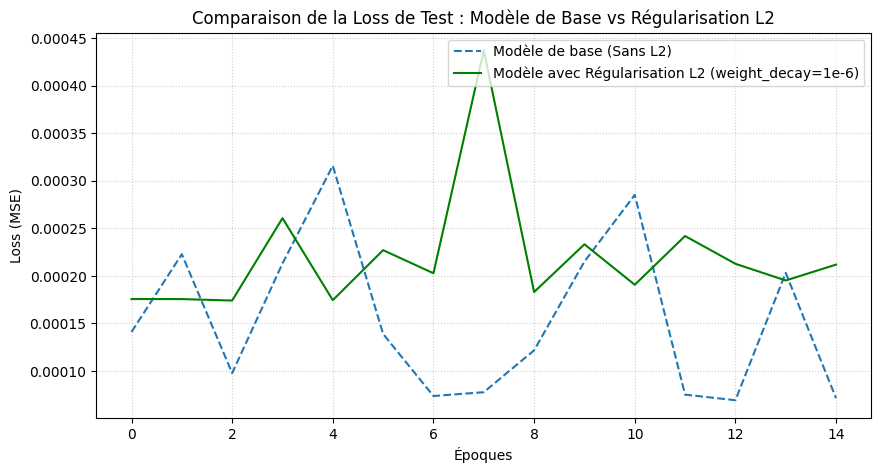

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# 1. Modèle standard (sans Dropout ni BatchNorm)
class BaselineMLP(nn.Module):
    def __init__(self, input_dim):
        super(BaselineMLP, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        return self.net(x)

# 2. Instanciation du modèle pour la régularisation L2
model_l2 = BaselineMLP(input_dim=4)

# 3. Fonction d'entraînement avec L2 (weight_decay)
def train_with_l2(model, train_loader, test_loader, epochs=15, lr=0.001, weight_decay=1e-6):
    criterion = nn.MSELoss()
    # Activation de L2 via l'argument weight_decay dans l'optimiseur
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    
    history = {'train_loss': [], 'test_loss': [], 'train_r2': [], 'test_r2': []}
    
    for epoch in range(epochs):
        # Mode Entraînement
        model.train()
        running_loss = 0.0
        y_true_train, y_pred_train = [], []
        
        for X_b, y_b in train_loader:
            optimizer.zero_grad()
            outputs = model(X_b)
            loss = criterion(outputs, y_b)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * X_b.size(0)
            y_true_train.extend(y_b.numpy())
            y_pred_train.extend(outputs.detach().numpy())
            
        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_r2 = r2_score(y_true_train, y_pred_train)
        
        # Mode Évaluation
        model.eval()
        running_test_loss = 0.0
        y_true_test, y_pred_test = [], []
        
        with torch.no_grad():
            for X_b, y_b in test_loader:
                outputs = model(X_b)
                loss = criterion(outputs, y_b)
                running_test_loss += loss.item() * X_b.size(0)
                y_true_test.extend(y_b.numpy())
                y_pred_test.extend(outputs.numpy())
                
        epoch_test_loss = running_test_loss / len(test_loader.dataset)
        epoch_test_r2 = r2_score(y_true_test, y_pred_test)
        
        history['train_loss'].append(epoch_train_loss)
        history['test_loss'].append(epoch_test_loss)
        history['train_r2'].append(epoch_train_r2)
        history['test_r2'].append(epoch_test_r2)
        
        print(f"Époque {epoch+1:02d}/{epochs:02d} | Train Loss: {epoch_train_loss:.4f} | Test Loss: {epoch_test_loss:.4f} | Test R2: {epoch_test_r2:.4f}")
        
    return history

# 4. Lancement de l'entraînement avec régularisation L2 (weight_decay=1e-3)
history_l2 = train_with_l2(model_l2, train_loader, test_loader, epochs=15, weight_decay=1e-3)

# 5. Graphique comparatif : Modèle de base vs Modèle L2
plt.figure(figsize=(10, 5))
plt.plot(history_base['test_loss'], label='Modèle de base (Sans L2)', linestyle='--')
plt.plot(history_l2['test_loss'], label='Modèle avec Régularisation L2 (weight_decay=1e-6)', color='green')
plt.title('Comparaison de la Loss de Test : Modèle de Base vs Régularisation L2')
plt.xlabel('Époques')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# Part two multi class classification:

## 1. Apply the per-processing technics and the given dataset to clean,

## 2. Apply the Exploratory data analysis technics to understand and visualize the given Dataset.

## 3. Apply data augmentation technics to balance the given Dataset.


## 4. Establish a Deep Neural network Architecture by using PyTorch library to handle the multi


## 5. By using GridSearch tool from sklearn library chose the best hyper-parameters (learning rate ,optimizers, epoch, model architecture, etc) that will give an efficient model.

## 6. Visualize the two graph (Loss / Epochs) and (Accuracy / Epochs) for both training and test data, give your interpretation.

## 7. Calculate metrics like accuracy, sensitivity, f1 score, etc, on both training and test dataset.


## 8. Apply several regularization techniques on your architecture then compare the obtained resultwith the first model.